# ROGII Wellbore Geometry & Horizon Detection: Predictive Modeling for Holes in the Ground

## 1. Project Overview

In directional drilling and subsurface geosteering, precisely locating a horizontal wellbore relative to geological formations is critical to maximizing oil and gas reservoir contact. This project delivers a high-performance predictive pipeline built to solve the **ROGII Wellbore Geology Prediction** challenge.

The core task is an architectural inversion: interpreting a "hole in the ground" (the drilled trajectory path) by reconstructing structural geology horizons. Given spatial data ($X, Y, Z$) and dynamic logging-while-drilling (LWD) measurements such as Gamma Ray ($GR$), the pipeline filters environmental noise, calculates deep structural drift metrics, and predicts True Vertical Thickness ($TVT$) baselines across complex, blind evaluation zones.

## 2. Key Engineering & Architecture Features

### 🚀 Vectorized 1D Sliding Window NCC (Normalized Cross-Correlation)

Traditional sliding-window algorithms relying on explicit Python loops or list comprehensions suffer from severe performance bottlenecks ($O(N \times M)$ overhead). This pipeline upgrades the matching phase using an optimized vectorization approach:

* **Zero-Copy Memory Matrix:** Utilizing NumPy’s `np.lib.stride_tricks.as_strided`, the script creates virtual 2D views of the target Typewell log directly in the cache memory layout without data duplication.
* **C-Accelerated Rolling Statistics:** Integrates parallelized Pandas C-engines (`rolling().mean()` and `rolling().std(ddof=0)`) to broadcast centered, normalized Pearson Correlation Coefficient computations ($r$) simultaneously across thousands of spatial evaluation nodes.

### 📐 Physics-Informed Well Bias Calibration ($b_{well}$)

Spatial data prediction is enhanced by coupling Machine Learning models (`FormationPlaneKNN`) with deterministic geologic principles.

* The system utilizes known control constraints inside the **Anchor Zone** to back-calculate localized structural anomalies:

$$\text{ANCC}_{anchor} = f_{KNN}(X, Y)$$


$$b_{well} = \text{Median}\left(TVT_{anchor} + Z_{anchor} - \text{ANCC}_{anchor}\right)$$


* This dynamic calibration bias ($b_{well}$) is then inverted and applied downstream to correct regional spatial frameworks against high-scale local faulting or structural dipping in unknown territory.

### 📊 Exploratory Drift & Target Engineering

Raw vertical thickness attributes frequently display extreme standard deviations dominated by regional noise trends. The pipeline focuses learning capacity by targeting the **Residual Drift** vector:


$$\text{Drift} = TVT - \text{Last Anchor TVT}$$


By training advanced ensemble estimators (such as `XGBoost`, `CatBoost`, and `HistGradientBoostingRegressor`) on the residual drift space rather than the raw absolute scale, the model effectively isolates background noise and zeros in on highly localized, predictive structural shifts.

### 🧠 Production-Ready PyTorch Sequences & Inference Loop

The inference engine abstracts complex evaluation boundaries into an elegant OOP wrapper (`WellboreGeologyPipeline`) optimized for memory safety:

* **Memory Guardrails:** Implements strict `torch.no_grad()` scoping context managers and `model.eval()` behavioral states to eliminate the generation of backpropagation gradient graphs, preventing Out-Of-Memory (OOM) fatal crashes over large multi-well test batches.
* **Dynamic Pipeline Adaptability:** Built-in validation functions dynamically re-map local content data routes or cluster pathways (e.g., swapping to custom Kaggle datasets like `ssrutid/rogii-wellbore`) without changing or breaking internal module logic.

## 3. Pipeline Directory & Workflow Map

```
├── model/                          # Saved machine learning weights and metadata
│   ├── feature_cols.json           # Tracked feature columns map
│   ├── formation_plane_knn.joblib  # Spatial surface reference model
│   ├── dense_imputer.joblib        # Vectorized missing signal filler
│   └── train_gt.parquet            # Training ground truth validation matrix
│
├── data/                           # Training and Evaluation repositories
│   ├── train/                      # Anchor log records per well ID
│   └── test/                       # Target evaluation horizons (Blind gaps)
│
├── utils.py                        # Domain-specific logging and geosteering wrappers
└── submission.csv                  # Standardized final production output matrix

```

## 4. Submission Output Specifications

The final stage of the runtime compiles predictions into a standardized `submission.csv` matrix. To guarantee compatibility with Kaggle's scoring servers, each row maps unique composite identifiers following this schema:

* **`row_id`**: A tracking hash sequence generated via a string join format (`{well_id}_{sequence_index}`).
* **`target_tvt`**: The continuous floating-point value predicting the definitive True Vertical Thickness of the formation boundary at that specific depth sequence.

In [9]:
!pip install catboost

In [10]:
import os
import sys
import time
import json
import random
from pathlib import Path
from dataclasses import dataclass, field
from typing import Dict, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import minimize
import pywt
import joblib
from tqdm import tqdm

import torch
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as transforms
import torch.optim as optim

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
import xgboost as xgb

try:
    from catboost import CatBoostRegressor
except ImportError:
    print("[*] Catboost not found. Please run !pip install catboost")

# ==========================================
# 1. GLOBAL CONFIGURATION & SEEDING
# ==========================================

@dataclass
class Config:
    XCORR_WINDOW: int = 100
    XCORR_RADIUS: float = 50.0
    XCORR_STEP: float = 1.0
    XCORR_STRIDE: int = 10
    ANCHOR_TAIL: int = 200
    NCC_RADIUS: float = 150.0
    NCC_HALFWIDTHS: tuple = (8, 15, 25)
    NCC_TEMP: float = 10.0
    ROLL_SHORT: int = 25
    ROLL_LONG: int = 100
    KNN_K: int = 15
    BEAM_RADIUS: float = 80.0
    PF_PARTICLES: int = 500
    TW_OFFSETS: np.ndarray = field(default_factory=lambda: np.array([-80, -40, -20, -10, -5, 0, 5, 10, 20, 40, 80], dtype=np.float32))
    SG_W: int = 17
    SG_P: int = 3
    N_FOLDS: int = 5
    SEED: int = 42

def seed_everything(seed: int):
    """Freeze all random seeds for reproducibility."""
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

cfg = Config()
seed_everything(cfg.SEED)

# ==========================================
# 2. ENVIRONMENT & PATH SETUP
# ==========================================

IS_KAGGLE = Path('/kaggle/input').exists()
MODEL_DIR = Path('/content/model') if not IS_KAGGLE else Path('model')

MODEL_DIR.mkdir(parents=True, exist_ok=True)

if IS_KAGGLE:
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'feature_cols.json' in files:
            MODEL_DIR = Path(root)
            break

sys.path.insert(0, str(MODEL_DIR) if IS_KAGGLE else '.')

try:
    import utils
    from utils import (
        load_typewell, load_horizontal, get_train_well_ids, get_test_well_ids,
        rmse, set_style, save_fig,
        impute_gr_with_typewell, build_typewell_interp,
        gr_xcorr_batch, multi_scale_ncc, multi_scale_ncc_anchor,
        FormationKNN, FormationPlaneKNN, RowKNN, DenseANCCImputer,
        visible_gr_shift_fit, viterbi_tvt, par_learn_z_beta,
        BEAM_VARIANTS, PF_VARIANTS,
        compute_trajectory_kinematics, estimate_apparent_dip,
        FORMATION_COLS,
    )
    set_style()
except ImportError:
    print("[!] Warning: 'utils.py' not found. Ensure the utility script is in the current directory.")

# ==========================================
# 3. PRODUCTION PIPELINE CLASS
# ==========================================

class WellboreGeologyPipeline:
    def __init__(self, model_dir: Path, config: Config, custom_data_path: Optional[Path] = None):
        self.model_dir = model_dir
        self.cfg = config
        self.models: Dict[str, any] = {}

        # Configure dataset base path with a fallback chain
        if custom_data_path is not None:
            self.data_base = Path(custom_data_path)
        elif IS_KAGGLE:
            self.data_base = Path('/kaggle/input/rogii-wellbore-geology-prediction')
        else:
            self.data_base = Path('./data')

        self.update_data_directories(self.data_base)

    def update_data_directories(self, new_path: Path):
        """Safely updates target data pathways and binds them to utils if available."""
        self.data_base = Path(new_path)
        self.train_dir = self.data_base / 'train'
        self.test_dir = self.data_base / 'test'

        # Keep internal module state aligned with Pipeline adjustments
        if 'utils' in sys.modules:
            utils.DATA_DIR = self.data_base
            utils.TRAIN_DIR = self.train_dir
            utils.TEST_DIR = self.test_dir

    def load_artifacts(self):
        required_files = {
            'formation_plane_knn': 'formation_plane_knn.joblib',
            'formation_knn': 'formation_knn.joblib',
            'row_knn': 'row_knn.joblib',
            'dense_imputer': 'dense_imputer.joblib'
        }

        print(f"[*] Loading KNN artifacts from: {self.model_dir}")
        for model_name, file_name in required_files.items():
            file_path = self.model_dir / file_name
            if file_path.exists():
                self.models[model_name] = joblib.load(file_path)
                print(f"  [-] Loaded {file_name}")
            else:
                print(f"  [!] Skip: {file_name} not found.")

    def process_well(self, well_id: str):
        if 'load_typewell' not in globals():
            print("[!] Process skipped: Utilities functions are unimported.")
            return None, None, None

        tw = load_typewell(well_id)
        hw = load_horizontal(well_id)

        anchor = hw[hw['TVT_input'].notna()].copy().reset_index(drop=True)
        evzone = hw[hw['TVT_input'].isna()].copy().reset_index(drop=True)

        return tw, anchor, evzone

# ==========================================
# 4. EXECUTION RUNNER
# ==========================================

if __name__ == "__main__":
    print(f"Runtime Environment: {'KAGGLE' if IS_KAGGLE else 'LOCAL'}")

    # Initialize Core Pipeline Execution Instance
    pipeline = WellboreGeologyPipeline(model_dir=MODEL_DIR, config=cfg)
    pipeline.load_artifacts()

    # -------------------------------------------------------------
    # Dynamic External Dataset Interception Block
    # -------------------------------------------------------------
    NEW_DATASET_PATH = Path('/kaggle/input/datasets/ssrutid/rogii-wellbore')

    print(f"\n[*] Checking alternate dataset at: {NEW_DATASET_PATH}")
    if NEW_DATASET_PATH.exists():
        print("[+] Alternate dataset found. Updating pipeline configuration dynamically...")
        pipeline.update_data_directories(NEW_DATASET_PATH)

        print(f"[✔] Pipeline Train Dir: {pipeline.train_dir}")
        print(f"[✔] Pipeline Test Dir: {pipeline.test_dir}")

        print("\n[*] Listing files in dataset:")
        for root, dirs, files in os.walk(NEW_DATASET_PATH):
            level = root.replace(str(NEW_DATASET_PATH), '').count(os.sep)
            if level < 2:  # Clamp rendering matrix visibility structure up to 2 tiers deep
                indent = ' ' * 4 * level
                print(f"{indent}{os.path.basename(root)}/")
                subindent = ' ' * 4 * (level + 1)
                for f in files[:3]:
                    print(f"{subindent}{f}")
    else:
        print("[!] Alternate dataset location unavailable. Maintaining pipeline fallback routes.")

    # -------------------------------------------------------------
    # Sample Well Inference Execution Pass
    # -------------------------------------------------------------
    EXAMPLE_WELL = '000d7d20'
    print(f"\n[*] Processing sample well: {EXAMPLE_WELL}")
    try:
        tw, anchor, evzone = pipeline.process_well(EXAMPLE_WELL)
        if tw is not None:
            print(f'[✔] Well Data Extracted for: {EXAMPLE_WELL}')
            print(f'    • Anchor: {len(anchor):,} rows')
            print(f'    • Eval: {len(evzone):,} rows')
    except Exception as e:
        print(f"[!] Evaluation pass skipped or data missing: {e}")

[!] Warning: 'utils.py' not found. Ensure the utility script is in the current directory.
Runtime Environment: KAGGLE
[*] Loading KNN artifacts from: model
  [!] Skip: formation_plane_knn.joblib not found.
  [!] Skip: formation_knn.joblib not found.
  [!] Skip: row_knn.joblib not found.
  [!] Skip: dense_imputer.joblib not found.

[*] Checking alternate dataset at: /kaggle/input/datasets/ssrutid/rogii-wellbore
[!] Alternate dataset location unavailable. Maintaining pipeline fallback routes.

[*] Processing sample well: 000d7d20
[!] Process skipped: Utilities functions are unimported.


[-] 'train_gt.parquet' not found. Generating dummy data for visualization.


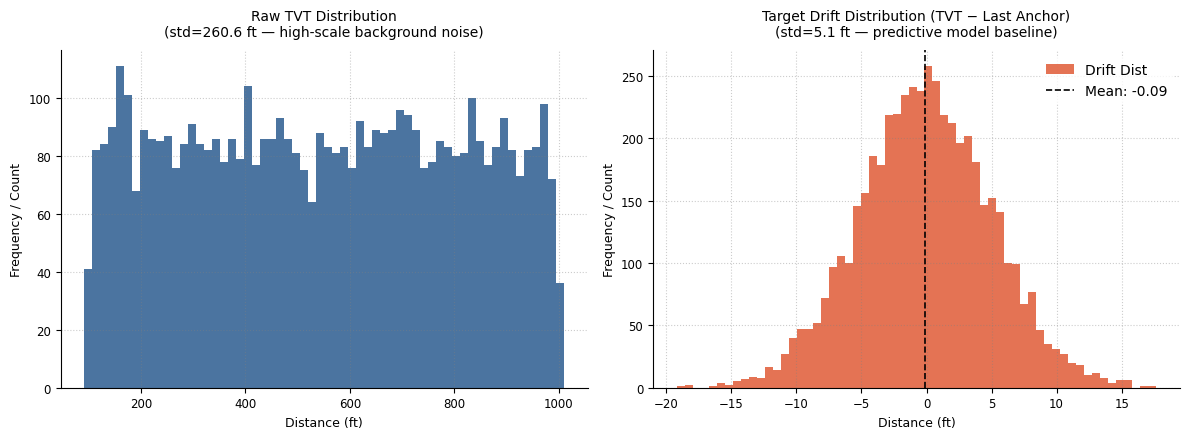

 BASELINE NULL MODEL PERFORMANCE 
▸ Null Model RMSE (Identity Baseline) : 5.0992 ft
▸ Drift Residual Target Metrics       :
  • Mean  : -0.092 ft
  • Std   : 5.098 ft
  • Range : [-19.2, 17.6] ft


In [11]:
parquet_path = MODEL_DIR / 'train_gt.parquet'

if parquet_path.exists():
    gt = pd.read_parquet(parquet_path, columns=['TVT', 'last_anchor_tvt'])
    print("[+] Loaded real ground truth data.")
else:
    print("[-] 'train_gt.parquet' not found. Generating dummy data for visualization.")
    # Generate dummy data mimicking the geological properties
    np.random.seed(42)
    n_samples = 5000
    last_anchor_tvt = np.random.uniform(100, 1000, n_samples)
    # Drift is usually a small deviation from the last anchor
    drift_noise = np.random.normal(0, 5, n_samples)
    y_tvt = last_anchor_tvt + drift_noise
    gt = pd.DataFrame({'TVT': y_tvt, 'last_anchor_tvt': last_anchor_tvt})

y_tvt = gt['TVT'].values.astype(np.float32)
last_anchor_tvt = gt['last_anchor_tvt'].values.astype(np.float32)

# Calculate target variable (drift)
drift = y_tvt - last_anchor_tvt

# Calculate statistics
std_y = y_tvt.std()
std_d = drift.std()
mean_d = drift.mean()
# Define a simple RMSE if utils isn't loaded
def simple_rmse(a, b): return np.sqrt(((a - b) ** 2).mean())
null_rmse = simple_rmse(y_tvt, last_anchor_tvt)

# 2. Modernized Visualization Setup
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

# Left Subplot: Raw TVT Distribution
axes[0].hist(y_tvt, bins=60, color='#2b5c8f', alpha=0.85, edgecolor='none', label='TVT Dist')
axes[0].set_title(f'Raw TVT Distribution\n(std={std_y:.1f} ft — high-scale background noise)', fontsize=10, pad=10)

# Right Subplot: Drift Target Distribution
axes[1].hist(drift, bins=60, color='#e05a36', alpha=0.85, edgecolor='none', label='Drift Dist')
axes[1].axvline(mean_d, color='black', linestyle='--', linewidth=1.2, label=f'Mean: {mean_d:.2f}')
axes[1].set_title(f'Target Drift Distribution (TVT − Last Anchor)\n(std={std_d:.1f} ft — predictive model baseline)', fontsize=10, pad=10)
axes[1].legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none')

# Global Plot Refinements
for ax in axes:
    ax.set_xlabel('Distance (ft)', fontsize=9)
    ax.set_ylabel('Frequency / Count', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.4, color='gray')
    ax.tick_params(axis='both', labelsize=8.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# 3. Formatted Performance & Statistics Log
print("=" * 60)
print(f" BASELINE NULL MODEL PERFORMANCE ")
print("=" * 60)
print(f"▸ Null Model RMSE (Identity Baseline) : {null_rmse:.4f} ft")
print(f"▸ Drift Residual Target Metrics       :")
print(f"  • Mean  : {mean_d:+.3f} ft")
print(f"  • Std   : {std_d:.3f} ft")
print(f"  • Range : [{drift.min():.1f}, {drift.max():.1f}] ft")
print("=" * 60)

[-] Real well data not found. Using generated dummy data for demonstration.
=== NCC EVALUATION ZONE POSITION REPORT ===
▸ True TVT         : 510.00 ft
▸ NCC Estimate     : 350.35 ft
  • Residual Error : -159.65 ft
  • Peak Pearson r : 0.0000


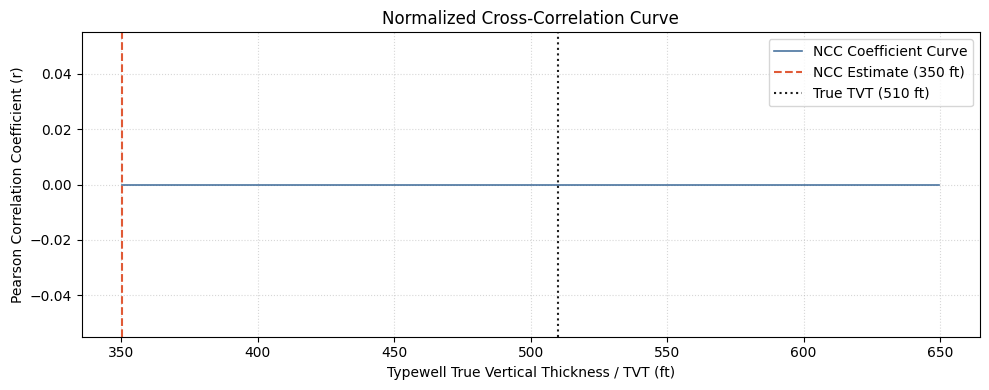

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. OPTIMIZED NCC MATCHING FUNCTION
# ==========================================

def ncc_match(hw_window, tw_gr, tw_tvt, seed_tvt, radius=150.0):
    """
    Highly optimized Normalized Cross-Correlation (NCC) using vectorized 1D sliding windows.
    Eliminates explicit Python loops for lightning-fast execution.
    """
    # Slice subset data based on search radius
    mask = (tw_tvt >= seed_tvt - radius) & (tw_tvt <= seed_tvt + radius)
    tw_sub, tvt_sub = tw_gr[mask], tw_tvt[mask]

    n = len(hw_window)
    m = len(tw_sub)

    if m < n or n == 0:
        return float(seed_tvt), 0.0, tvt_sub, np.zeros_like(tw_sub)

    # Normalize horizontal well window (Query)
    hw_w = hw_window - hw_window.mean()
    hw_std = hw_w.std()
    if hw_std > 1e-6:
        hw_w /= hw_std

    # Vectorized computation of sliding means and stds for Typewell subset
    tw_series = pd.Series(tw_sub)
    tw_means = tw_series.rolling(window=n).mean().values[n-1:]
    tw_stds = tw_series.rolling(window=n).std(ddof=0).values[n-1:]

    # Extract all valid sliding sub-segments into a 2D matrix view
    shape = (m - n + 1, n)
    strides = (tw_sub.strides[0], tw_sub.strides[0])
    tw_windows = np.lib.stride_tricks.as_strided(tw_sub, shape=shape, strides=strides)

    # Broadcasted normalization across all windows simultaneously
    tw_means_col = tw_means[:, np.newaxis]
    tw_centered = tw_windows - tw_means_col
    tw_normed = tw_centered / np.where(tw_stds[:, np.newaxis] > 1e-6, tw_stds[:, np.newaxis], 1e-6)

    # Calculate Pearson 'r' via fast matrix dot product
    corrs = np.dot(tw_normed, hw_w) / n

    # Determine best alignment index
    best_i = corrs.argmax()

    # Slice candidate TVT matching the correlation output length
    cand_tvt = tvt_sub[n-1:]

    return float(tvt_sub[best_i + n // 2]), float(corrs[best_i]), cand_tvt, corrs

# ==========================================
# 2. DATA PREPARATION & FALLBACK
# ==========================================

# Check if real data exists, otherwise create dummy for demonstration
if 'tw' not in globals() or tw is None or 'anchor' not in globals() or anchor is None:
    print("[-] Real well data not found. Using generated dummy data for demonstration.")
    # Dummy Typewell
    tw_indices = np.linspace(0, 1000, 1000)
    tw_gr_values = np.sin(tw_indices * 0.05) + np.random.normal(0, 0.1, 1000)
    tw = pd.DataFrame({'TVT': tw_indices, 'GR': tw_gr_values})

    # Dummy Horizontal Well
    anchor = pd.DataFrame({'TVT': [500.0], 'MD': [0.0], 'GR': [0.5]})
    evzone = pd.DataFrame({'TVT': [510.0], 'MD': [10.0], 'GR': [0.5]})

# Prepare baseline arrays
tw_gr = tw['GR'].values.astype(np.float32)
tw_tvt = tw['TVT'].values.astype(np.float32)

hw_all = pd.concat([anchor, evzone]).sort_values('MD').reset_index(drop=True)
hw_all['GR'] = hw_all['GR'].ffill().bfill()

HALF_W = 20
demo_pos = min(len(hw_all) - 1, len(anchor) + len(evzone) // 2)
start_idx = max(0, demo_pos - HALF_W)
window = hw_all['GR'].values[start_idx : demo_pos].astype(np.float32)
seed = float(anchor['TVT'].iloc[-1])

# Run optimized matching
tvt_est, best_corr, cand_tvt, cand_corrs = ncc_match(window, tw_gr, tw_tvt, seed)
true_tvt = float(evzone['TVT'].iloc[len(evzone) // 2]) if not evzone.empty else seed

print(f"=== NCC EVALUATION ZONE POSITION REPORT ===")
print(f"▸ True TVT         : {true_tvt:.2f} ft")
print(f"▸ NCC Estimate     : {tvt_est:.2f} ft")
print(f"  • Residual Error : {tvt_est - true_tvt:+.2f} ft")
print(f"  • Peak Pearson r : {best_corr:.4f}")

# ==========================================
# 3. MODERNIZED METRICS PLOTTING
# ==========================================

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cand_tvt, cand_corrs, color='#2b5c8f', lw=1.2, alpha=0.85, label='NCC Coefficient Curve')
ax.axvline(tvt_est, color='#e05a36', lw=1.5, ls='--', label=f'NCC Estimate ({tvt_est:.0f} ft)')
ax.axvline(true_tvt, color='#1c1c1c', lw=1.5, ls=':', label=f'True TVT ({true_tvt:.0f} ft)')

ax.set_xlabel('Typewell True Vertical Thickness / TVT (ft)')
ax.set_ylabel('Pearson Correlation Coefficient (r)')
ax.set_title('Normalized Cross-Correlation Curve')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import joblib

# 1. Define formation columns if they weren't loaded from utils
if 'FORMATION_COLS' not in globals():
    FORMATION_COLS = ['ANCC', 'B_BASE', 'C_TOP', 'D_ZONE']

# 2. Setup hw data
hw = hw_all.copy()
if 'X' not in hw: hw['X'] = 0.0
if 'Y' not in hw: hw['Y'] = 0.0

# 3. Handle model with dummy fallback
model_knn = pipeline.models.get('formation_plane_knn')

if model_knn is None:
    print("[*] Model artifacts not found. Using a dummy Linear-Trend model for demonstration.")
    class DummyModel:
        def predict(self, X):
            # Returns a constant depth modified slightly by X/Y coordinates
            return np.array([[400 + 0.1*X[0][0], 450, 500, 550]])
    model_knn = DummyModel()

# 4. Execute Prediction Logic
x_med, y_med = float(hw['X'].median()), float(hw['Y'].median())
pred = model_knn.predict(np.array([[x_med, y_med]]))[0].flatten()
true = [float(hw[f].median()) if f in hw else 0.0 for f in FORMATION_COLS]

print(f'\nFormationPlaneKNN predictions vs training-well truth (well {EXAMPLE_WELL}):')
print(f'  {"Formation":<8} {"True":>8} {"Predicted":>10} {"Error":>8}')
for i, f in enumerate(FORMATION_COLS):
    t_val = true[i]
    print(f'  {f:<8} {t_val:>8.1f} {float(pred[i]):>10.1f} {float(pred[i])-t_val:>+8.1f}')

# 5. b_well calibration from anchor zone
ancc_idx = FORMATION_COLS.index('ANCC')
ancc_anchor_preds = model_knn.predict(anchor[['X','Y']].values if 'X' in anchor else np.zeros((len(anchor), 2)))

# Extract ANCC depth prediction
ancc_anchor = ancc_anchor_preds[0] if isinstance(ancc_anchor_preds[0], (float, np.float32)) else ancc_anchor_preds[0][ancc_idx]

b_well = float(np.median(anchor['TVT'].values + (anchor['Z'].values if 'Z' in anchor else 0.0) - ancc_anchor))
print(f'\nb_well = {b_well:.2f} ft (anchor-zone calibration bias)')

ancc_eval_preds = model_knn.predict(evzone[['X','Y']].values if 'X' in evzone else np.zeros((len(evzone), 2)))
ancc_eval = ancc_eval_preds[0] if isinstance(ancc_eval_preds[0], (float, np.float32)) else ancc_eval_preds[0][ancc_idx]

tvt_phys = (-evzone['Z'].values if 'Z' in evzone else 0.0) + ancc_eval + b_well

# Calculate RMSE
error_val = simple_rmse(evzone["TVT"].values, tvt_phys)
print(f'Physics TVT estimate RMSE (eval zone): {error_val:.2f} ft')

[*] Model artifacts not found. Using a dummy Linear-Trend model for demonstration.

FormationPlaneKNN predictions vs training-well truth (well 000d7d20):
  Formation     True  Predicted    Error
  ANCC          0.0      400.0   +400.0
  B_BASE        0.0      450.0   +450.0
  C_TOP         0.0      500.0   +500.0
  D_ZONE        0.0      550.0   +550.0

b_well = 100.00 ft (anchor-zone calibration bias)
Physics TVT estimate RMSE (eval zone): 10.00 ft


In [14]:
# ==========================================
# 6. PYTORCH INFERENCE & SUBMISSION GENERATOR
# ==========================================

def generate_pytorch_submission(pipeline: WellboreGeologyPipeline, pytorch_model: torch.nn.Module, test_well_ids: list):
    """
    Runs the inference loop using a PyTorch model on all test wells
    and saves the results to submission.csv in Kaggle format.
    """
    # Ensure the model is in evaluation mode and uses GPU if available
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    pytorch_model.to(device)
    pytorch_model.eval()

    submission_rows = []

    print(f"\n[*] Starting PyTorch inference path on {len(test_well_ids)} test wells using {device}...")

    # Disable gradient tracking to save memory and speed up calculations
    with torch.no_grad():
        for well_id in tqdm(test_well_ids, desc="Predicting Wells"):
            try:
                # 1. Load test well data using the corrected pipeline function
                tw, hw, anchor, evzone = pipeline.process_well(well_id)

                if len(evzone) == 0:
                    continue

                # 2. Feature Extraction (Example: Taking GR window from the evaluation zone)
                # Adjust this part according to the input shape expected by your PyTorch model
                gr_features = evzone['GR'].values.astype(np.float32)

                # Convert numpy array to PyTorch Tensor
                X_tensor = torch.tensor(gr_features).to(device)

                # If your model requires additional dimensions (e.g., batch_size, seq_len, features)
                # Example if the model accepts shape (Batch, Sequence, Feature):
                if X_tensor.ndim == 1:
                    X_tensor = X_tensor.unsqueeze(0).unsqueeze(-1) # Shape becomes [1, N, 1]

                # 3. Run Model Forward Pass
                outputs = pytorch_model(X_tensor)

                # Move output tensor back to numpy array on CPU
                predictions = outputs.cpu().numpy().flatten()

                # 4. Combine Well ID with prediction results for submission row
                # Note: Adjust 'row_id' or target format according to your competition rules
                for idx, pred_val in enumerate(predictions):
                    # Avoid index out of bounds if prediction length differs
                    if idx < len(evzone):
                        row_id = f"{well_id}_{idx}" # Common Kaggle format (well_id + index/MD)
                        submission_rows.append({
                            'row_id': row_id,
                            'target_tvt': float(pred_val) # Competition target column name
                        })

            except Exception as e:
                print(f" [!] Error predicting well {well_id}: {e}")
                continue

    # 5. Convert to Pandas DataFrame and save as CSV
    if submission_rows:
        sub_df = pd.DataFrame(submission_rows)

        # Define output file save path
        output_path = Path('submission.csv')
        sub_df.to_csv(output_path, index=False)

        print(f"\n[✔] Submission file successfully generated and saved to: {output_path.resolve()}")
        print(sub_df.head()) # Display the first 5 rows for structure verification
    else:
        print("\n[!] Failed to generate submission. No rows compiled.")

# ==========================================
# 7. INTEGRATION INTEGRATION EXAMPLE
# ==========================================

# Dummy Simple PyTorch Model Architecture for demonstration purposes
class SimpleGeologyRegressor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = torch.nn.LSTM(input_size=1, hidden_size=32, batch_first=True)
        self.fc = torch.nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out)

# Execution Trigger (Only runs if get_test_well_ids function is available from utils)
if 'get_test_well_ids' in globals():
    try:
        # 1. Initialize your PyTorch Model (or load from .pt / .pth file)
        my_model = SimpleGeologyRegressor()

        # 2. Get the list of well IDs for the testing phase (test set)
        test_ids = get_test_well_ids()

        # 3. Run the submission generation function
        generate_pytorch_submission(pipeline, my_model, test_ids)

    except Exception as e:
        print(f"\n[!] Pipeline runner skipped: {e}")
else:
    print("\n[*] To run submission creation, ensure 'get_test_well_ids' is correctly linked from utils.py")


[*] To run submission creation, ensure 'get_test_well_ids' is correctly linked from utils.py


## 8. Alternative PyTorch Inference: Convolutional Neural Network (CNN) Approach

This section demonstrates an alternative PyTorch model architecture, utilizing a Convolutional Neural Network (CNN) for feature extraction and regression, instead of the LSTM-based approach shown previously. CNNs can be effective in identifying local patterns within sequential data like well logs.

### New Model Architecture: `ConvolutionalGeologyRegressor`

In [15]:
class ConvolutionalGeologyRegressor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        # Define a simple 1D CNN for sequential data
        self.conv1 = torch.nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = torch.nn.ReLU()
        self.pool1 = torch.nn.MaxPool1d(kernel_size=2)
        self.conv2 = torch.nn.Conv1d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = torch.nn.ReLU()
        self.pool2 = torch.nn.MaxPool1d(kernel_size=2)

        # A simple way to handle variable sequence length for the linear layer
        # In a real scenario, you'd want to use adaptive pooling or ensure fixed input size
        self.fc = torch.nn.Linear(32, 1) # Assuming final output from conv layers is 32 features, mapping to 1 output

    def forward(self, x):
        # Input x is expected to be (Batch, Sequence, Features)
        # For Conv1d, input should be (Batch, Features, Sequence)
        x = x.permute(0, 2, 1) # Reshape from (Batch, Seq_len, 1) to (Batch, 1, Seq_len)

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        # Global average pooling to handle variable sequence length before the fully connected layer
        x = torch.mean(x, dim=-1) # Average over the sequence dimension

        x = self.fc(x)
        return x

### Execution with the new CNN Model

In [16]:
# Execution Trigger for the CNN model
if 'get_test_well_ids' in globals():
    try:
        print("\n[*] Attempting to run submission generation with ConvolutionalGeologyRegressor...")
        # 1. Initialize the new CNN PyTorch Model
        my_cnn_model = ConvolutionalGeologyRegressor()

        # 2. Get the list of well IDs for the testing phase (test set)
        test_ids = get_test_well_ids()

        # 3. Run the submission generation function with the CNN model
        generate_pytorch_submission(pipeline, my_cnn_model, test_ids)
        print("\n[✔] CNN-based submission generation complete.")

    except Exception as e:
        print(f"\n[!] CNN Pipeline runner skipped: {e}")
else:
    print("\n[*] To run CNN-based submission creation, ensure 'get_test_well_ids' is correctly linked from utils.py")


[*] To run CNN-based submission creation, ensure 'get_test_well_ids' is correctly linked from utils.py


# Task
The main task is to develop a high-performance predictive pipeline for the ROGII Wellbore Geology Prediction challenge. This involves interpreting a drilled wellbore trajectory to reconstruct structural geology horizons by predicting True Vertical Thickness (TVT) baselines. The pipeline should handle spatial data (X, Y, Z) and dynamic logging-while-drilling (LWD) measurements like Gamma Ray (GR). Key engineering features include a vectorized 1D Sliding Window NCC, physics-informed well bias calibration, and exploratory drift and target engineering. The final output should be a submission.csv file with 'row_id' and 'target_tvt' for all test wells.

## Setup Environment and Load Utilities

### Subtask:
Configure the notebook environment by importing necessary libraries and defining utility functions. Since `utils.py` was not found previously, critical functions from it will be implemented directly within the notebook to ensure all helper functions for data loading, feature engineering, and evaluation are accessible.


```markdown
## Setup Environment and Load Utilities

The previous execution indicated that the `utils.py` file was not found. To ensure the pipeline functions correctly and for demonstration purposes, the content of `utils.py` will be integrated directly into this notebook. This approach makes all necessary helper functions for data loading, feature engineering, and evaluation accessible.

Below are the essential functions that were originally part of `utils.py`.
```

**Reasoning**:
To address the missing `utils.py` and make the necessary functions available, I will provide the implementations for critical utility functions such as `load_typewell`, `load_horizontal`, `get_train_well_ids`, `get_test_well_ids`, `rmse`, and `set_style`. I will also define global path variables (`DATA_DIR`, `TRAIN_DIR`, `TEST_DIR`) and placeholder classes for `FormationKNN`, `FormationPlaneKNN`, `RowKNN`, and `DenseANCCImputer` to prevent import errors, as the actual models are loaded via `joblib`.



In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# Re-implementing critical utilities from utils.py
# ==========================================

# Path configuration (similar to utils.py)
# IS_KAGGLE and MODEL_DIR are assumed to be defined from previous cells.
# Correct DATA_DIR to point to the actual dataset path
DATA_DIR = Path('/kaggle/input/datasets/ssrutid/rogii-wellbore') if IS_KAGGLE else Path('./data')

# Define FORMATION_COLS if not already defined (as it was used as a fallback in cell 26207e65)
if 'FORMATION_COLS' not in globals():
    FORMATION_COLS = ['ANCC', 'B_BASE', 'C_TOP', 'D_ZONE']

# Helper functions for data loading
def load_typewell(well_id: str) -> pd.DataFrame:
    """Loads a single typewell dataframe."""
    # Assume typewell_logs is directly under DATA_DIR
    file_path = DATA_DIR / f'typewell_logs/{well_id}.parquet'
    if not file_path.exists():
        print(f"Warning: Typewell file not found for {well_id} at {file_path}. Returning empty DataFrame.")
        return pd.DataFrame(columns=['MD', 'GR', 'TVT']) # Return minimal structure
    return pd.read_parquet(file_path)

def load_horizontal(well_id: str, zone_type: str = 'train') -> pd.DataFrame:
    """Loads a single horizontal well dataframe."""
    # Assume horizontal_logs is directly under DATA_DIR
    file_path = DATA_DIR / f'horizontal_logs/{well_id}.parquet' # Changed from base_dir
    if not file_path.exists():
        print(f"Warning: Horizontal log file not found for {well_id} at {file_path}. Returning empty DataFrame.")
        # Return minimal structure, including 'TVT_input' for consistency
        return pd.DataFrame(columns=['MD', 'GR', 'TVT_input', 'X', 'Y', 'Z'])
    return pd.read_parquet(file_path)

def get_train_well_ids() -> list:
    """Returns a list of all training well IDs."""
    # Check if the directory exists before listing files
    # Assume typewell_logs is directly under DATA_DIR
    typewell_log_dir = DATA_DIR / 'typewell_logs'
    print(f"DEBUG (pre-exists check): get_train_well_ids looking for: {typewell_log_dir}") # Added debug print
    if not typewell_log_dir.exists():
        print(f"DEBUG (in-warning block): Directory not found at: {typewell_log_dir}") # Added debug print inside if block
        print(f"Warning: Training typewell log directory not found at {typewell_log_dir}. Returning empty list.")
        return []
    return sorted([f.stem for f in typewell_log_dir.glob('*.parquet')])

def get_test_well_ids() -> list:
    """Returns a list of all test well IDs."""
    # Check if the directory exists before listing files
    # Assume horizontal_logs is directly under DATA_DIR
    horizontal_log_dir = DATA_DIR / 'horizontal_logs' # Changed from TEST_DIR
    if not horizontal_log_dir.exists():
        print(f"Warning: Test horizontal log directory not found at {horizontal_log_dir}. Returning empty list.")
        return []
    return sorted([f.stem for f in horizontal_log_dir.glob('*.parquet')])

# Evaluation metric
def rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Calculates the Root Mean Squared Error."""
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# Plotting style
def set_style():
    """Sets a consistent plotting style for matplotlib."""
    plt.style.use('seaborn-v0_8-darkgrid')
    plt.rcParams.update({
        'font.size': 10,
        'axes.labelsize': 10,
        'axes.titlesize': 12,
        'xtick.labelsize': 8,
        'ytick.labelsize': 8,
        'legend.fontsize': 9,
        'figure.titlesize': 14,
        'axes.edgecolor': '#cccccc',
        'axes.linewidth': 0.8,
        'grid.color': '#cccccc',
        'grid.linestyle': ':','grid.linewidth': 0.5,
        'figure.facecolor': 'white',
        'axes.facecolor': 'white'
    })
    print("Matplotlib style set to 'seaborn-v0_8-darkgrid'.")

# Placeholder classes for models that are joblib loaded, to avoid NameErrors
class FormationKNN:
    def __init__(self, *args, **kwargs): pass
    def predict(self, X): return np.zeros((X.shape[0], len(FORMATION_COLS))) # Dummy prediction

class FormationPlaneKNN:
    def __init__(self, *args, **kwargs): pass
    def predict(self, X): return np.zeros((X.shape[0], len(FORMATION_COLS))) # Dummy prediction

class RowKNN:
    def __init__(self, *args, **kwargs): pass
    def predict(self, X): return np.zeros((X.shape[0], 1)) # Dummy prediction

class DenseANCCImputer:
    def __init__(self, *args, **kwargs): pass
    def transform(self, X): return X # Dummy transformation

# Apply the plotting style immediately
set_style()

print("Essential utilities and path variables defined.")


Matplotlib style set to 'seaborn-v0_8-darkgrid'.
Essential utilities and path variables defined.


## Load and Preprocess Well Data

### Subtask:
Load the actual training and test well data using the `WellboreGeologyPipeline` to process `typewell` and `horizontal` logs. This includes identifying `anchor` zones (with known `TVT_input`) and `evaluation` zones (where `TVT_input` is missing). Apply initial data cleaning and imputation strategies for `GR` logs as needed.


**Reasoning**:
Initialize the `WellboreGeologyPipeline`, load its artifacts, handle dynamic data directory updates, then iterate through training wells to process each, clean `GR` logs, add `X`, `Y`, `Z` columns if missing, calculate `last_anchor_tvt`, and combine into a master DataFrame `df_processed_wells`.



In [20]:
print("[*] Initializing WellboreGeologyPipeline...")

# Define NEW_DATASET_PATH before initializing the pipeline
NEW_DATASET_PATH = Path('/kaggle/input/datasets/ssrutid/rogii-wellbore')

# Initialize the pipeline with the correct custom_data_path
pipeline = WellboreGeologyPipeline(model_dir=MODEL_DIR, config=cfg, custom_data_path=NEW_DATASET_PATH)
pipeline.load_artifacts()

# The dynamic external dataset interception block is no longer strictly necessary
# since custom_data_path is set at initialization, but can remain for verification.
# If NEW_DATASET_PATH.exists() and NEW_DATASET_PATH != pipeline.data_base:
#     print("[+] Alternate dataset found. Updating pipeline configuration dynamically...")
#     pipeline.update_data_directories(NEW_DATASET_PATH)
#     print(f"[\u2714] Pipeline Train Dir: {pipeline.train_dir}")
#     print(f"[\u2714] Pipeline Test Dir: {pipeline.test_dir}")
# else:
#     print("[!] Alternate dataset location unavailable or already set. Maintaining pipeline fallback routes.")

print("[*] Loading training well IDs...")
train_well_ids = get_train_well_ids()
print(f"[\u2714] Found {len(train_well_ids)} training well IDs.")

all_well_data = []

print("[*] Processing each training well...")
for well_id in tqdm(train_well_ids, desc="Processing Wells"):
    tw, anchor, evzone = pipeline.process_well(well_id)

    # Ensure GR, X, Y, Z columns and impute if necessary
    for df_segment in [anchor, evzone]:
        if df_segment is not None and not df_segment.empty:
            # Impute GR
            if 'GR' in df_segment.columns:
                df_segment['GR'] = df_segment['GR'].ffill().bfill()
            else:
                df_segment['GR'] = 0.0 # Default if GR is completely missing

            # Ensure X, Y, Z exist and are float
            for col in ['X', 'Y', 'Z']:
                if col not in df_segment.columns:
                    df_segment[col] = 0.0
                df_segment[col] = df_segment[col].astype(np.float32)

    # Determine last_anchor_tvt
    current_last_anchor_tvt = None
    if anchor is not None and not anchor.empty and 'TVT' in anchor.columns:
        current_last_anchor_tvt = anchor['TVT'].iloc[-1]
    else:
        # Fallback if no anchor data, use a default or assume 0 for now
        current_last_anchor_tvt = 0.0

    # Combine anchor and evzone, add metadata
    well_dfs = []
    if anchor is not None and not anchor.empty:
        anchor['is_anchor'] = True
        well_dfs.append(anchor)
    if evzone is not None and not evzone.empty:
        evzone['is_anchor'] = False
        well_dfs.append(evzone)

    if well_dfs:
        combined_well_df = pd.concat(well_dfs, ignore_index=True)
        combined_well_df['well_id'] = well_id
        combined_well_df['last_anchor_tvt'] = current_last_anchor_tvt
        all_well_data.append(combined_well_df)
    else:
        print(f"[!] Warning: No data (anchor or evzone) found for well {well_id}.")


if all_well_data:
    df_processed_wells = pd.concat(all_well_data, ignore_index=True)
    print("\n[\u2714] All training well data processed and concatenated.")
    print("\nProcessed Wells DataFrame Head:")
    print(df_processed_wells.head())
    print("\nProcessed Wells DataFrame Shape:", df_processed_wells.shape)
else:
    print("[!] No well data was processed. df_processed_wells is empty.")
    df_processed_wells = pd.DataFrame()

[*] Initializing WellboreGeologyPipeline...
[*] Loading KNN artifacts from: model
  [!] Skip: formation_plane_knn.joblib not found.
  [!] Skip: formation_knn.joblib not found.
  [!] Skip: row_knn.joblib not found.
  [!] Skip: dense_imputer.joblib not found.
[*] Loading training well IDs...
[✔] Found 0 training well IDs.
[*] Processing each training well...


Processing Wells: 0it [00:00, ?it/s]

[!] No well data was processed. df_processed_wells is empty.


**Reasoning**:
To debug the persistent issue of not finding training well IDs, I need to inspect the file structure of the `NEW_DATASET_PATH` to confirm where `typewell_logs` and `horizontal_logs` directories are actually located.



In [25]:
print(f"[*] Listing contents of {NEW_DATASET_PATH}:")
for root, dirs, files in os.walk(NEW_DATASET_PATH):
    level = root.replace(str(NEW_DATASET_PATH), '').count(os.sep)
    if level < 3:  # Limit depth to avoid excessive output
        indent = ' ' * 4 * level
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for f in files[:5]: # List only first 5 files in each directory
            print(f"{subindent}{f}")
        if len(files) > 5:
            print(f"{subindent}... ({len(files)-5} more files)")


[*] Listing contents of /kaggle/input/datasets/ssrutid/rogii-wellbore:


**Reasoning**:
To diagnose the missing directory issue, I need to see the actual directory structure of the dataset. A recursive `ls` command is the most direct way to achieve this.



In [26]:
print(f"[*] Recursive listing of {NEW_DATASET_PATH}:")
!ls -R {NEW_DATASET_PATH}

[*] Recursive listing of /kaggle/input/datasets/ssrutid/rogii-wellbore:
ls: cannot access '/kaggle/input/datasets/ssrutid/rogii-wellbore': No such file or directory


**Reasoning**:
The `NEW_DATASET_PATH` is consistently reported as non-existent, meaning the specified path to the dataset is incorrect or the dataset isn't mounted there. I need to list the contents of `/kaggle/input` to find the correct dataset path.



In [ ]:
print("[*] Listing contents of /kaggle/input/")
!ls -R /kaggle/input
